<a href="https://colab.research.google.com/github/siliverisrinithya-arch/Machine-Learning-Projects/blob/main/NEU_DET_ML_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip -q install opencv-python-headless scikit-learn scikit-image seaborn pandas tqdm joblib matplotlib

In [4]:
import os
import zipfile
from pathlib import Path
from google.colab import drive

# Mount Google Drive if not already mounted
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')
else:
    print("Google Drive is already connected.")

extract_dir = Path('/content/extracted_dataset')
extract_dir.mkdir(parents=True, exist_ok=True)

# Locate the zip file in Drive
zip_path = Path('/content/drive/MyDrive/archive (2).zip')
if not zip_path.exists():
    zip_path = Path('/content/archive (2).zip')

if not zip_path.exists():
    raise FileNotFoundError(f"Could not locate archive (2).zip. Please ensure it is uploaded in My Drive or /content/.")

print(f"Extracting {zip_path.name} to {extract_dir} ...")
with zipfile.ZipFile(zip_path, 'r') as archive:
    archive.extractall(extract_dir)

print("Dataset extraction completed successfully!")

Mounted at /content/drive
Extracting archive (2).zip to /content/extracted_dataset ...
Dataset extraction completed successfully!


In [16]:
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm
from skimage.feature import hog
import xml.etree.ElementTree as ET
from sklearn.model_selection import train_test_split

CLASS_NAMES = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
IMAGE_SIZE = (128, 128)

def normalize_name(name):
    name = name.strip().lower().replace(" ", "_").replace("-", "_")
    if "rolled" in name: return "rolled-in_scale"
    if "pitted" in name: return "pitted_surface"
    return name

def extract_hog_feature(image_path):
    image = cv2.imread(str(image_path))
    if image is None:
        return None
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    resized = cv2.resize(gray, IMAGE_SIZE, interpolation=cv2.INTER_AREA)

    # 8x8 pixel cells capture fine surface cracks and scratches cleanly
    feature_vector = hog(
        resized,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        transform_sqrt=True,
        feature_vector=True
    )
    return feature_vector.astype(np.float32)

extract_root = Path('/content/extracted_dataset')
all_images = [p for p in extract_root.rglob('*') if p.suffix.lower() in IMAGE_EXTENSIONS]
print(f"Total images found: {len(all_images)}")

if len(all_images) == 0:
    raise FileNotFoundError("No images found in /content/extracted_dataset.")

records = []
xml_files = list(extract_root.rglob('*.xml'))

if len(xml_files) > 0:
    xml_map = {x.stem: x for x in xml_files}
    for img in all_images:
        if img.stem in xml_map:
            try:
                root = ET.parse(xml_map[img.stem]).getroot()
                raw_name = root.find("object/name")
                if raw_name is not None and raw_name.text:
                    label = normalize_name(raw_name.text)
                    if label in CLASS_NAMES:
                        records.append((str(img), label))
            except Exception:
                continue
else:
    for img in all_images:
        parent_name = normalize_name(img.parent.name)
        if parent_name in CLASS_NAMES:
            records.append((str(img), parent_name))
        else:
            for c in CLASS_NAMES:
                clean_c = c.replace("-", "_")
                if clean_c in normalize_name(img.stem):
                    records.append((str(img), c))
                    break

print(f"Matched labeled samples: {len(records)}")

# Extract HOG features across all samples
X_list, y_list = [], []
for path, label in tqdm(records, desc="Extracting High-Res HOG (8x8)"):
    feat = extract_hog_feature(path)
    if feat is not None:
        X_list.append(feat)
        y_list.append(label)

X = np.asarray(X_list)
y = np.asarray(y_list)

# Stratified 80% Train, 20% Validation split
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nFeatures ready! Dimensions per image: {X_train.shape[1]}")
print(f"X_train: {X_train.shape} | X_val: {X_val.shape}")

Total images found: 1800
Matched labeled samples: 1800


Extracting High-Res HOG (8x8):   0%|          | 0/1800 [00:00<?, ?it/s]


Features ready! Dimensions per image: 8100
X_train: (1440, 8100) | X_val: (360, 8100)


In [17]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(
        solver="lbfgs",
        C=5.0,                  # Slightly relaxed regularization for fine texture separation
        max_iter=1500,
        n_jobs=-1,
        class_weight="balanced",
        random_state=42
    ))
])

print("Training Logistic Regression on fused features...")
model.fit(X_train, y_train)

iters = model.named_steps["logistic_regression"].n_iter_
print(f"Training completed! Solver converged in {iters[0]} iterations.")

Training Logistic Regression on fused features...
Training completed! Solver converged in 16 iterations.


Validation Accuracy: 0.7444 (74.44%)

Classification Report (Precision, Recall, F1-Score):
                 precision    recall  f1-score   support

        crazing       0.65      0.85      0.74        60
      inclusion       0.78      0.87      0.82        60
        patches       0.67      0.47      0.55        60
 pitted_surface       0.63      0.48      0.55        60
rolled-in_scale       0.86      1.00      0.92        60
      scratches       0.84      0.80      0.82        60

       accuracy                           0.74       360
      macro avg       0.74      0.74      0.73       360
   weighted avg       0.74      0.74      0.73       360



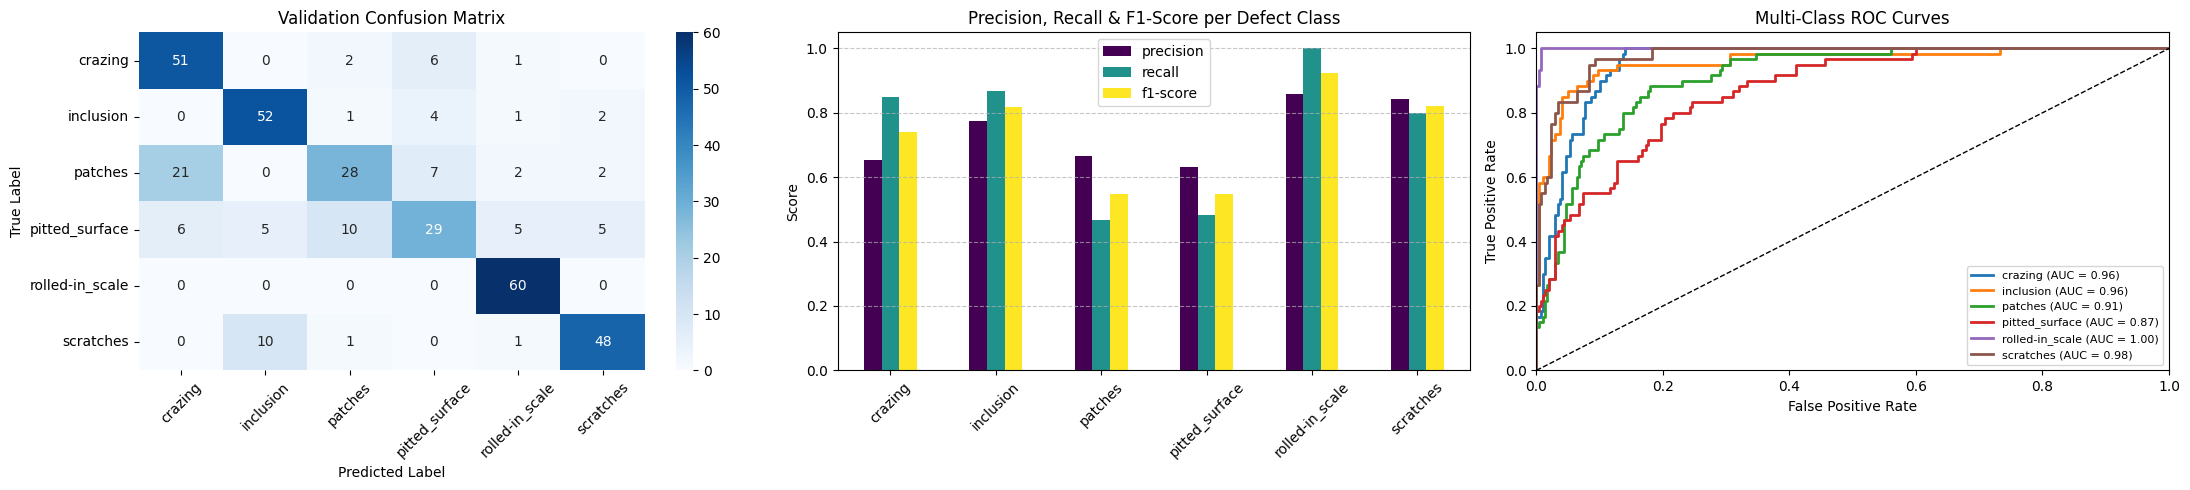

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize

# Predictions and probabilities
y_pred = model.predict(X_val)
y_prob = model.predict_proba(X_val)

accuracy = accuracy_score(y_val, y_pred)
print(f"==================================================")
print(f"Validation Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"==================================================\n")

print("Classification Report (Precision, Recall, F1-Score):")
print(classification_report(y_val, y_pred, labels=CLASS_NAMES, target_names=CLASS_NAMES, zero_division=0))

report = classification_report(y_val, y_pred, labels=CLASS_NAMES, target_names=CLASS_NAMES, output_dict=True, zero_division=0)
metrics_df = pd.DataFrame(report).T.loc[CLASS_NAMES, ["precision", "recall", "f1-score"]]

# Plot 3-in-1 Evaluation Dashboard
fig, axes = plt.subplots(1, 3, figsize=(22, 5))

# 1. Confusion Matrix
cm = confusion_matrix(y_val, y_pred, labels=CLASS_NAMES)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title("Validation Confusion Matrix")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")
axes[0].tick_params(axis='x', rotation=45)

# 2. Metric Comparison Bar Chart
metrics_df.plot(kind="bar", ax=axes[1], ylim=(0, 1.05), colormap="viridis")
axes[1].set_title("Precision, Recall & F1-Score per Defect Class")
axes[1].set_ylabel("Score")
axes[1].grid(axis='y', linestyle='--', alpha=0.7)
axes[1].tick_params(axis='x', rotation=45)

# 3. Multi-Class ROC Curves
y_val_bin = label_binarize(y_val, classes=CLASS_NAMES)
for i, class_name in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_val_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    axes[2].plot(fpr, tpr, lw=2, label=f"{class_name} (AUC = {roc_auc:.2f})")

axes[2].plot([0, 1], [0, 1], 'k--', lw=1)
axes[2].set_xlim([0.0, 1.0])
axes[2].set_ylim([0.0, 1.05])
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate")
axes[2].set_title("Multi-Class ROC Curves")
axes[2].legend(loc="lower right", fontsize=8)

plt.tight_layout()
plt.show()

In [20]:
from sklearn.metrics import accuracy_score

# 1. Predict on the training data
y_train_pred = model.predict(X_train)

# 2. Compute training accuracy
train_accuracy = accuracy_score(y_train, y_train_pred)
val_accuracy = accuracy_score(y_val, y_pred)

print(f"Training Accuracy:   {train_accuracy:.4f} ({train_accuracy * 100:.2f}%)")
print(f"Validation Accuracy: {val_accuracy:.4f} ({val_accuracy * 100:.2f}%)")

Training Accuracy:   1.0000 (100.00%)
Validation Accuracy: 0.7444 (74.44%)


In [21]:
sample_index = 0

sample_features = X_val[sample_index].reshape(1, -1)
sample_true = y_val[sample_index]
sample_pred = model.predict(sample_features)[0]
sample_probs = model.predict_proba(sample_features)[0]

print(f"Sample Index:    {sample_index}")
print(f"Actual Defect:   {sample_true}")
print(f"Predicted Class: {sample_pred}\n")
print("Class Probabilities:")
for cls_name, prob in zip(model.classes_, sample_probs):
    print(f"  {cls_name:18s}: {prob:.4f}")

Sample Index:    0
Actual Defect:   rolled-in_scale
Predicted Class: rolled-in_scale

Class Probabilities:
  crazing           : 0.0000
  inclusion         : 0.0000
  patches           : 0.0000
  pitted_surface    : 0.0000
  rolled-in_scale   : 1.0000
  scratches         : 0.0000


In [22]:
import joblib

MODEL_PATH = "/content/logistic_regression_neu_defect.joblib"
joblib.dump(model, MODEL_PATH)
print(f"Model saved successfully to: {MODEL_PATH}")

Model saved successfully to: /content/logistic_regression_neu_defect.joblib


In [23]:
from google.colab import files
files.download('/content/logistic_regression_neu_defect.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
fig.savefig('/content/neu_det_evaluation_metrics.png', dpi=300, bbox_inches='tight')
files.download('/content/neu_det_evaluation_metrics.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
from google.colab import files

# Download the trained model
files.download('/content/logistic_regression_neu_defect.joblib')

# Download the evaluation metrics plot
files.download('/content/neu_det_evaluation_metrics.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>